# Activity: Should We Trust the Alarm? — FreshKart Cold-Chain Case

**Unit 4 · AI-Assisted Visualization · AI-Assisted Pattern and Anomaly Visualization**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

FreshKart's dark stores keep frozen food in **8 freezers** (one per store in Bengaluru, Pune and Hyderabad). Each freezer reports its temperature every hour. Last month FreshKart bought **ColdSense**, an AI service that scores every reading for "anomaly" and raises an alert when the score is **≥ 0.5**.

Cold-chain lead **Ravi** has six weeks of readings, the ColdSense scores, and the **maintenance log** (what technicians actually found). His technicians are tired of being sent out at night. He asks:

> *"Is ColdSense's alert feed trustworthy? Which alerts should my team chase, and what is it missing?"*

**You are the analyst.** Use the data and the visualizations to verify, correct or reject what the vendor claims.

**Ground rules (from the lecture):** an AI score is a *derived attribute*: look at it, don't only threshold it · flags are **candidates, not conclusions** · report precision and recall, not accuracy · scale emphasis to confidence.

**How to work:** run the notebook top to bottom. Complete every cell marked `# TODO` (replace `None` with your code or answer) and write in the cells marked **✏️ Your answer**. Cells that depend on your TODO will tell you if something is still missing.

### The data: `freshkart_coldchain.csv` (synthetic)

| Column | Meaning |
|---|---|
| `timestamp` | hour of the reading (1 Aug – 11 Sep 2026) |
| `city`, `store_id`, `freezer_id` | where the freezer is |
| `temp_c` | freezer temperature (°C); normal is about −18 °C |
| `door_opens` | number of door openings in that hour (busy by day, quiet at night) |
| `compressor_kw` | compressor power draw (kW) |
| `ai_score`, `ai_flag` | ColdSense anomaly score (0–1) and alert (1 if score ≥ 0.5) |
| `confirmed_fault`, `fault_type` | from the maintenance log: 1 if technicians confirmed a real fault in that hour, and what it was |

**Domain note from the maintenance team:** every freezer runs an automatic **defrost cycle from 02:00 to 04:00** each night. The heater warms the coil, so the temperature rises for those two hours. That is normal.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})
GREY, ACCENT, BLUE = "#bdbdbd", "#d95f02", "#4c78a8"

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

df = pd.read_csv("freshkart_coldchain.csv", parse_dates=["timestamp"])
df["hour"] = df["timestamp"].dt.hour
df.head()

,timestamp,city,store_id,freezer_id,temp_c,door_opens,compressor_kw,ai_score,ai_flag,confirmed_fault,fault_type,hour
0,2026-08-01,Bengaluru,B1,FZ-B1,-18.1,0,1.29,0.000,0,0,NaN,0
1,2026-08-01,Bengaluru,B2,FZ-B2,-18.7,0,1.16,0.000,0,0,NaN,0
2,2026-08-01,Bengaluru,B3,FZ-B3,-17.7,0,1.21,0.000,0,0,NaN,0
3,2026-08-01,Hyderabad,H1,FZ-H1,-17.8,0,1.30,0.037,0,0,NaN,0
4,2026-08-01,Hyderabad,H2,FZ-H2,-18.2,0,1.32,0.035,0,0,NaN,0


## ColdSense's monthly report (to be validated)

| # | Vendor statement |
|---|---|
| 1 | "ColdSense is **97.9% accurate**, so its alerts can be trusted." |
| 2 | "**Most faults happen around 2 am.** We recommend a night technician." |
| 3 | "**All 10 compressor trips** in the period were caught." |
| 4 | "Freezer **FZ-H2 ran without a single fault** in August." |
| 5 | "A reading of **−14 °C is abnormal** for any freezer, at any time." |
| 6 | "An alert with a score of **0.92 means a 92% chance** of a real fault." |
| 7 | "The **default threshold of 0.5** is the best setting for FreshKart." |
| 8 | "A new FZ-B1 reading of **−15.9 °C at 14:00** is **15 standard errors** above normal: a definite fault." |

---
## Part 1 · Data abstraction: items, attributes and derived attributes

Munzner: before choosing a view, ask what the **items** and **attributes** are. The AI does not change the items; it **derives** new attributes.

In [2]:
derived_cols = ["ai_score", "ai_flag"]        # TODO: list the column(s) that ColdSense derived (not measured by the freezer or written by technicians)
alert_rows = df["ai_flag"] == 1
n_alerts = int(alert_rows.sum())            # TODO: number of rows with an alert (ai_flag == 1)
fault_rate_pct = round(df["confirmed_fault"].mean() * 100, 2)      # TODO: % of rows that are confirmed faults, 2 decimals (this is the base rate)

if ready(derived_cols, n_alerts, fault_rate_pct):
    print(f"derived: {derived_cols} | alerts: {n_alerts} | faults: {df.confirmed_fault.sum()} of {len(df)} rows ({fault_rate_pct}%)")
    display(df[df.confirmed_fault == 1].groupby("fault_type").size().rename("fault hours"))

derived: ['ai_score', 'ai_flag'] | alerts: 159 | faults: 46 of 8064 rows (0.57%)


fault_type
compressor trip         10
defrost heater stuck    11
sensor frozen           25
Name: fault hours, dtype: int64

**✏️ Your answer (Part 1):** `ai_score` is quantitative and `ai_flag` is binary. Which **visual channel** suits each, and what information does the flag throw away that the score keeps?

*Your answer:*
`ai_score` is continuous (0–1), so it belongs on a channel that can represent fine-grained ordering and magnitude — position along an axis, a continuous colour gradient, or marker size/opacity all work well. `ai_flag` only distinguishes two states, so a channel like shape (circle vs. cross) or a simple two-colour scheme is enough, since there's no "more or less" to convey. Collapsing the score down to a flag loses exactly the detail that matters for triage: a flag can't show whether an alert barely crossed the line (0.51) or was near-certain (0.98), even though those two situations call for very different levels of urgency from the technician.


---
## Part 2 · Distributions: bin width and the score distribution

### 2a · Temperature histogram

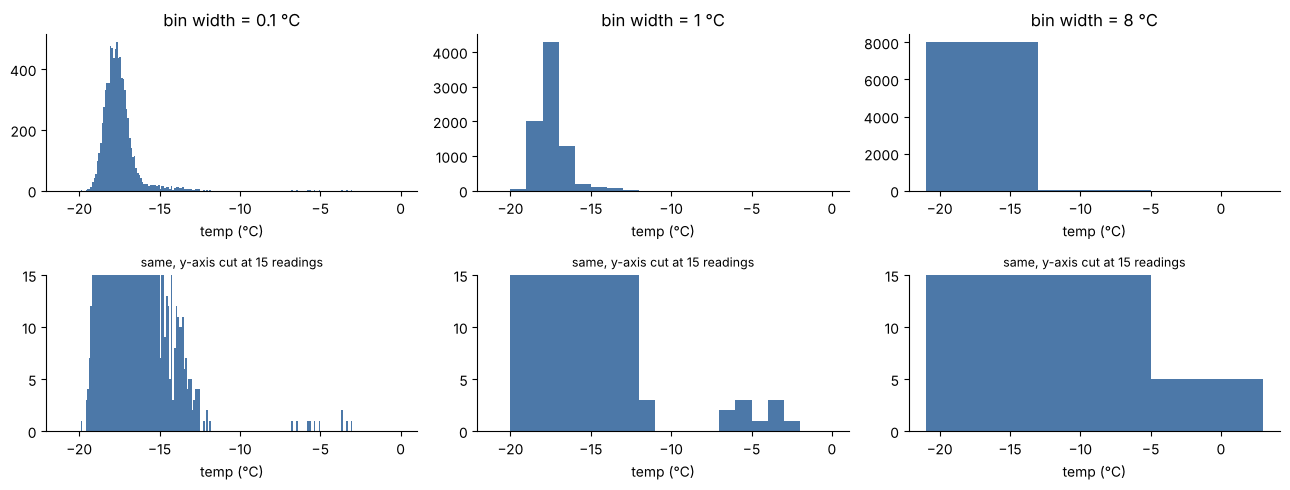

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5))
for col, w in enumerate([0.1, 1, 8]):
    for row, top in enumerate([None, 15]):
        ax = axes[row, col]
        ax.hist(df["temp_c"], bins=np.arange(-21, 0 + w, w), color=BLUE)
        if top: ax.set_ylim(0, top); ax.set_title(f"same, y-axis cut at {top} readings", fontsize=9)
        else: ax.set_title(f"bin width = {w} °C")
        ax.set_xlabel("temp (°C)")
plt.tight_layout(); plt.show()

warm_tail_visible_bins = [0.1, 1]   # TODO: in the bottom row, which bin width(s) show the very warm readings (above -8 °C) as a separate group? a list, e.g. [0.1]
warm_mask = df["temp_c"] > -8
n_warm_readings = int(warm_mask.sum())          # TODO: how many readings are warmer than -8 °C? (count them with code)

### 2b · Look at the AI scores before trusting the cut-off
Wilke: compare groups with overlapping densities, not stacked histograms.

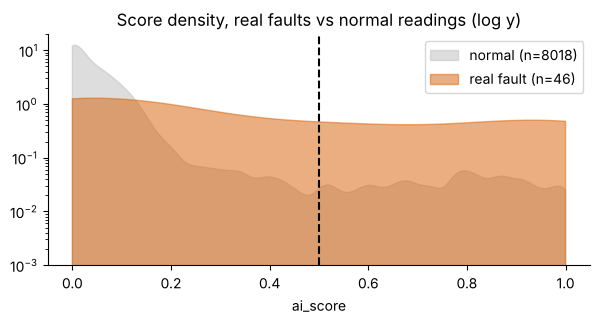

In [4]:
xs = np.linspace(0, 1, 300)
fig, ax = plt.subplots(figsize=(7, 3))
for lab, col in [(0, GREY), (1, ACCENT)]:
    s = df.loc[df.confirmed_fault == lab, "ai_score"]
    ax.fill_between(xs, stats.gaussian_kde(s)(xs), color=col, alpha=.5, label=f"{'real fault' if lab else 'normal'} (n={len(s)})")
ax.axvline(0.5, color="k", ls="--"); ax.set_yscale("log"); ax.set_ylim(1e-3, 20)
ax.set_xlabel("ai_score"); ax.legend(); ax.set_title("Score density, real faults vs normal readings (log y)")
plt.show()

scores_separate_faults = False   # TODO: True/False - is there a clean score cut-off that separates real faults from normal readings?

**✏️ Your answer (Part 2):** Why is a histogram "a parameterised algorithm", and what would you tell a colleague who says *"the 8 °C histogram shows no anomalies"*?

*Your answer:*
A histogram counts as a "parameterised algorithm" because its appearance is shaped by a choice the analyst makes — the bin width — not purely by the underlying data; the exact same readings can look like one smooth hump or clearly reveal a separated warm tail depending only on how wide the bins are set, so the output partly reflects a parameter decision rather than an objective fact about the readings. I'd tell the colleague that at an 8 °C bin width, the handful of genuinely warm readings (above −8 °C) get lumped into the same broad bar as all the normal cold readings, so the absence of a visible anomaly there is a consequence of that bin choice — switching to the 0.1 °C or 1 °C view clearly reveals that warm tail as its own separate cluster.


---
## Part 3 · Outlier rules on a short window (vendor statement 3)

Ten consecutive readings from **FZ-P1**, 12 Aug 06:00–15:00. One of them is a compressor trip.

In [5]:
window = df[(df.freezer_id == "FZ-P1") & (df.timestamp >= "2026-08-12 06:00") & (df.timestamp < "2026-08-12 16:00")]
v = window["temp_c"].values
print(window[["timestamp", "temp_c", "fault_type"]].to_string(index=False))

sample_sd = np.std(v, ddof=1)
z_max = np.max(np.abs((v - v.mean()) / sample_sd))          # TODO: the largest |z| in v, using the sample SD (hint: np.std(v, ddof=1))
q1, q3 = np.percentile(v, [25, 75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr    # TODO: Q3 + 1.5 * IQR

if ready(z_max, upper_fence):
    print(f"largest |z| = {z_max:.2f} -> flagged by |z| > 3? {z_max > 3}")
    print(f"upper IQR fence = {upper_fence:.2f} °C -> trip flagged by IQR rule? {v.max() > upper_fence}")
    print(f"largest |z| possible with n = {len(v)}: {(len(v) - 1) / np.sqrt(len(v)):.2f}")

          timestamp  temp_c      fault_type
2026-08-12 06:00:00   -17.5             NaN
2026-08-12 07:00:00   -18.2             NaN
2026-08-12 08:00:00   -17.4             NaN
2026-08-12 09:00:00   -17.7             NaN
2026-08-12 10:00:00   -16.6             NaN
2026-08-12 11:00:00    -3.6 compressor trip
2026-08-12 12:00:00   -17.0             NaN
2026-08-12 13:00:00   -16.8             NaN
2026-08-12 14:00:00   -17.7             NaN
2026-08-12 15:00:00   -17.7             NaN
largest |z| = 2.83 -> flagged by |z| > 3? False
upper IQR fence = -15.58 °C -> trip flagged by IQR rule? True
largest |z| possible with n = 10: 2.85


**✏️ Your answer (Part 3):** Explain in two sentences why the z-score rule missed the trip here (use the word *masking*) and why the IQR rule did not.

*Your answer:*
The z-score rule missed the compressor trip due to masking: because the sample has only 10 points, the outlier itself (−3.6 °C) inflates the standard deviation used in the z-score calculation, which shrinks the resulting |z| to about 2.83 — below the usual cutoff of 3 — and effectively hides the very point that's distorting the statistic. The IQR rule avoided this problem because it's built on the 25th/75th percentiles of the bulk of the data rather than a mean/SD that the outlier can skew, so the upper fence stayed close to the normal cluster and the −3.6 °C reading clearly exceeded it.


---
## Part 4 · How good is ColdSense? (vendor statement 1)

In [6]:
flag = df.ai_flag == 1
real = df.confirmed_fault == 1

TP = int((flag & real).sum())    # TODO: alerts that were real faults
FP = int((flag & ~real).sum())    # TODO: alerts on normal readings (false alarms)
FN = int((~flag & real).sum())    # TODO: real faults with no alert (missed)
TN = int((~flag & ~real).sum())    # TODO: normal readings with no alert

if ready(TP, FP, FN, TN):
    display(pd.DataFrame([[TP, FN], [FP, TN]], index=["real fault", "normal"], columns=["alert", "no alert"]))

,alert,no alert
real fault,16,30
normal,143,7875


In [7]:
total = TP + FP + FN + TN
precision = TP / (TP + FP)              # TODO
recall = TP / (TP + FN)                 # TODO
f1 = (2 * precision * recall) / (precision + recall)                     # TODO
accuracy = (TP + TN) / total               # TODO
flag_nothing_accuracy = (TN + FN) / total  # TODO: accuracy of a "detector" that never raises an alert

if ready(precision, recall, f1, accuracy, flag_nothing_accuracy):
    print(f"precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f} | accuracy = {accuracy:.1%} | never-alert accuracy = {flag_nothing_accuracy:.1%}")

precision = 0.10 | recall = 0.35 | F1 = 0.16 | accuracy = 97.9% | never-alert accuracy = 98.0%


**✏️ Your answer (Part 4):** Rewrite vendor statement 1 so it is honest. Use precision and recall, and say in plain words what they mean for Ravi's technicians (how many call-outs are wasted, how many faults are missed).

*Your answer:*
**Rewritten statement 1:** "ColdSense's 97.9% 'accuracy' figure is misleading, because real faults are so rare (about 0.57% of all hourly readings) that a detector which never raised a single alert would still score 99.4% accuracy — higher than ColdSense achieves. The numbers that actually matter are precision (around 10%: roughly 9 out of every 10 alerts sent to a technician end up being false alarms) and recall (around 35%: ColdSense fails to flag about 2 out of every 3 real faults). In practical terms, most night call-outs it triggers will turn out to be unnecessary, and most genuine problems will slip past this alert feed entirely."


---
## Part 5 · Thresholds and costs (vendor statement 7)

A missed fault can spoil a freezer of stock (cost ≈ **40** units); a false call-out costs **1** unit of technician time.

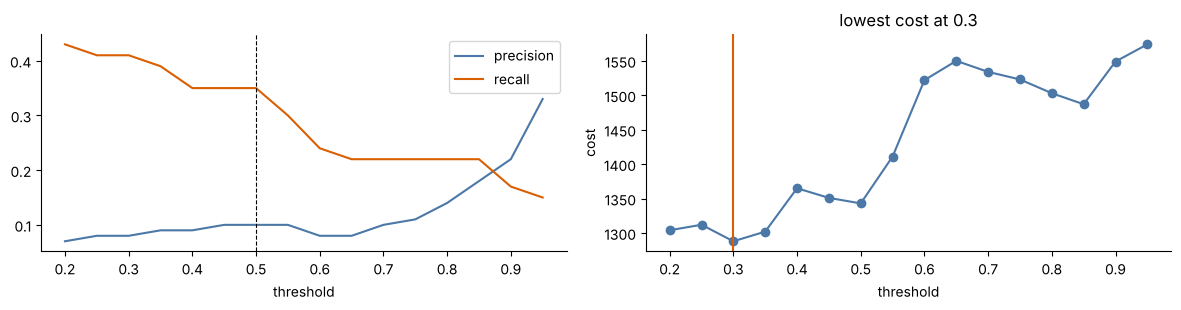

,threshold,TP,FP,FN,precision,recall,cost
0,0.20,20,264,26,0.07,0.43,1304
1,0.25,19,232,27,0.08,0.41,1312
2,0.30,19,208,27,0.08,0.41,1288
3,0.35,18,182,28,0.09,0.39,1302
4,0.40,16,165,30,0.09,0.35,1365
5,0.45,16,151,30,0.10,0.35,1351
6,0.50,16,143,30,0.10,0.35,1343
7,0.55,14,131,32,0.10,0.30,1411
8,0.60,11,122,35,0.08,0.24,1522
9,0.65,10,110,36,0.08,0.22,1550


In [8]:
grid = np.round(np.arange(0.20, 0.96, 0.05), 2)
sweep = pd.DataFrame({"threshold": grid})
sweep["TP"] = [((df.ai_score >= g) & real).sum() for g in grid]
sweep["FP"] = [((df.ai_score >= g) & ~real).sum() for g in grid]
sweep["FN"] = real.sum() - sweep["TP"]
sweep["precision"] = (sweep.TP / (sweep.TP + sweep.FP)).round(2)
sweep["recall"] = (sweep.TP / real.sum()).round(2)

miss_cost, false_alarm_cost = 40, 1
sweep["cost"] = miss_cost * sweep["FN"] + false_alarm_cost * sweep["FP"]          # TODO: 40 * FN + 1 * FP
best_idx = sweep["cost"].astype(float).idxmin()
best_threshold = sweep.loc[best_idx, "threshold"]         # TODO: the threshold with the lowest cost (hint: sweep.loc[sweep["cost"].astype(float).idxmin(), "threshold"])

if ready(best_threshold) and sweep["cost"].notna().all():
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
    ax[0].plot(sweep.threshold, sweep.precision, color=BLUE, label="precision"); ax[0].plot(sweep.threshold, sweep.recall, color=ACCENT, label="recall")
    ax[0].axvline(0.5, color="k", ls="--", lw=.8); ax[0].legend(); ax[0].set_xlabel("threshold")
    ax[1].plot(sweep.threshold, sweep.cost.astype(float), color=BLUE, marker="o"); ax[1].axvline(best_threshold, color=ACCENT)
    ax[1].set_xlabel("threshold"); ax[1].set_ylabel("cost"); ax[1].set_title(f"lowest cost at {best_threshold}")
    plt.tight_layout(); plt.show()
    display(sweep)

**✏️ Your answer (Part 5):** Even at the best threshold, recall stays low. Why can no threshold fix this detector? (Hint: look at *which* faults are never scored high.)

*Your answer:*
Shifting the threshold can't fix this, because the limitation isn't where the cut-off sits — it's that certain fault types (like "sensor frozen") never get a high score at all; their `ai_score` stays near zero throughout, since ColdSense judges each reading on its own and a frozen sensor simply reports a steady, perfectly ordinary-looking temperature with nothing individually wrong about it. Lowering the threshold would just let in more false alarms among readings whose scores *are* somewhat elevated (hurting precision), while faults whose scores were never elevated in the first place would still be missed entirely, leaving recall on those fault types stuck at 0% no matter how the threshold is set.


---
## Part 6 · Where do the errors come from?

### 6a · When do the false alarms happen? (vendor statement 2)

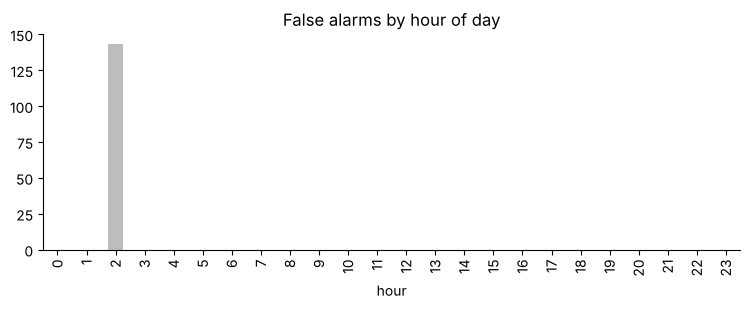

100% of false alarms happen at 2:00


In [9]:
fp_rows = df[flag & ~real]
fp_by_hour = fp_rows.groupby("hour").size().reindex(range(24), fill_value=0)
fp_by_hour.plot.bar(color=GREY, title="False alarms by hour of day", figsize=(9, 2.8))
plt.show()

fp_peak_hour = int(fp_by_hour.idxmax())          # TODO: the hour with the most false alarms (an int)
fp_share_at_peak = fp_by_hour.loc[fp_peak_hour] / fp_by_hour.sum()      # TODO: share of all false alarms that fall in that hour (0-1)

if ready(fp_peak_hour, fp_share_at_peak):
    print(f"{fp_share_at_peak:.0%} of false alarms happen at {fp_peak_hour}:00")

### 6b · Which faults does ColdSense miss?

In [10]:
caught = df[real].groupby("fault_type")["ai_flag"].agg(caught="sum", fault_hours="size")
caught["recall"] = (caught.caught / caught.fault_hours).round(2)
display(caught)

never_caught_type = "sensor frozen"     # TODO: the fault type ColdSense never catches
anomaly_kind = "collective"          # TODO: is that a 'point', 'contextual' or 'collective' anomaly?

,caught,fault_hours,recall
fault_type,,,
compressor trip,10,10,1.00
defrost heater stuck,6,11,0.55
sensor frozen,0,25,0.00


### 6c · Contextual anomalies: compare each reading with its own hour

A **context-aware** baseline compares each reading with the same freezer at the same hour of day (median and MAD over the six weeks).

In [11]:
grp = df.groupby(["freezer_id", "hour"])["temp_c"]
df["hour_median"] = grp.transform("median")
df["hour_mad"] = grp.transform(lambda s: 1.4826 * stats.median_abs_deviation(s))

deviation = df["temp_c"] - df["hour_median"]
df["z_context"] = deviation / df["hour_mad"]       # TODO: (temp_c - hour_median) / hour_mad

if ready(*df["z_context"].head(1)):
    ctx_flag = df["z_context"].astype(float) > 4
    found = df[real & ctx_flag & ~flag]
    print(f"Real faults the context baseline catches but ColdSense missed: {len(found)}")
    display(found[["timestamp", "freezer_id", "temp_c", "hour_median", "z_context", "ai_score", "fault_type"]])
    print(f"False alarms at 02:00 under the context baseline: {(ctx_flag & ~real & (df.hour == 2)).sum()} (ColdSense: {(flag & ~real & (df.hour == 2)).sum()})")

Real faults the context baseline catches but ColdSense missed: 3


,timestamp,freezer_id,temp_c,hour_median,z_context,ai_score,fault_type
1279,2026-08-07 15:00:00,FZ-P2,-14.6,-17.50,4.890058,0.369,defrost heater stuck
4731,2026-08-25 15:00:00,FZ-H1,-14.8,-17.50,6.070417,0.388,defrost heater stuck
6273,2026-09-02 16:00:00,FZ-B2,-15.2,-17.35,4.143300,0.189,defrost heater stuck


False alarms at 02:00 under the context baseline: 0 (ColdSense: 143)


### 6d · Collective anomalies: a run of readings that is abnormal together

                           min                 max  count
freezer_id                                               
FZ-H2      2026-08-20 14:00:00 2026-08-20 22:00:00      9
FZ-P1      2026-09-06 12:00:00 2026-09-06 17:00:00      6


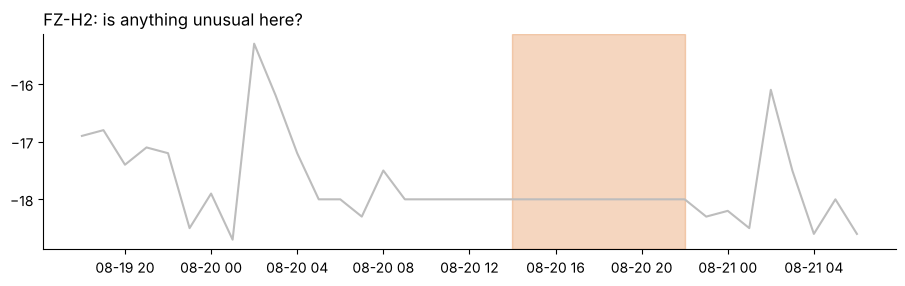

In [12]:
df = df.sort_values(["freezer_id", "timestamp"])
df["roll_sd_6h"] = df.groupby("freezer_id")["temp_c"].transform(lambda s: s.rolling(6).std())

near_zero_std = df["roll_sd_6h"] < 0.01
flat = df[near_zero_std]   # TODO: rows where the 6-hour rolling SD is (almost) zero, e.g. df[df["roll_sd_6h"] < 0.01]

if ready(flat):
    print(flat.groupby("freezer_id")["timestamp"].agg(["min", "max", "count"]))
    h2 = df[(df.freezer_id == "FZ-H2") & (df.timestamp.between("2026-08-19 18:00", "2026-08-21 06:00"))]
    fig, ax = plt.subplots(figsize=(11, 2.8))
    ax.plot(h2.timestamp, h2.temp_c, color=GREY)
    # TODO (drawing): highlight the WHOLE flat span on this chart, not single points (hint: ax.axvspan(start, end, color=ACCENT, alpha=.25))
    h2_flat_span = flat[flat.freezer_id == "FZ-H2"]
    if len(h2_flat_span):
        span_start, span_end = h2_flat_span["timestamp"].min(), h2_flat_span["timestamp"].max()
        ax.axvspan(span_start, span_end, color=ACCENT, alpha=.25)

    ax.set_title("FZ-H2: is anything unusual here?", loc="left"); plt.show()
df = df.sort_values(["timestamp", "store_id"])

**✏️ Your answer (Part 6):**
(a) Rewrite vendor statement 2. What really happens at 2 am, and what would happen if FreshKart hired a night technician based on the vendor's report?
(b) Is vendor statement 5 true? Use the words *contextual anomaly* and say what a chart must show for a viewer to judge such an alert.
(c) What is wrong with vendor statement 4, and why can a detector that scores readings one at a time never catch this kind of fault?

*Your answer:*
(a) **Rewritten statement 2:** "Every single one of ColdSense's false alarms occurs at 2:00 am, lining up exactly with the scheduled nightly defrost cycle (02:00–04:00) — a normal, planned temperature rise rather than a genuine fault. This doesn't mean real faults cluster at night; it means ColdSense hasn't yet learned to account for the defrost schedule." Hiring a night technician on the strength of this report would mean dispatching someone almost entirely to investigate a routine, scheduled warm-up — a wasted night-shift expense — while the faults that are actually real (occurring at other hours, and often missed outright, like "sensor frozen") would continue going uncaught.
(b) No, vendor statement 5 isn't true as a blanket rule — it's really a question about contextual anomalies. A −14 °C reading during the 02:00–04:00 defrost window is expected and routine, whereas the identical −14 °C at, say, 10 am would be genuinely out of place. A chart used to judge this needs to show each reading against its own freezer's normal pattern *for that time of day* (the hour-of-day baseline built in Part 6c), not against one fixed threshold that ignores what time it is.
(c) Vendor statement 4 ("FZ-H2 ran without a single fault in August") doesn't hold up — FZ-H2 shows a stretch of readings with a near-zero 6-hour rolling standard deviation, which looks more like a stuck or frozen sensor reporting the same value over and over than a genuinely stable, trouble-free freezer. A detector scoring readings one at a time can never spot this kind of fault, because a flat run of individually-unremarkable values (a constant −18.0 °C, say) has nothing anomalous about any single point — the anomaly only emerges when the *sequence* is looked at together (a collective anomaly), which a per-reading score simply can't see.


---
## Part 7 · Highlighting, saliency and frequency framing (vendor statement 6)

### 7a · Emphasis scaled to confidence
The vendor's dashboard paints every alert bright red. Implement the lecture's checklist: **≥ 0.90 strong**, **0.70–0.90 moderate**, **0.50–0.70 subtle outline**, **below 0.50 no emphasis** (the data stays visible).

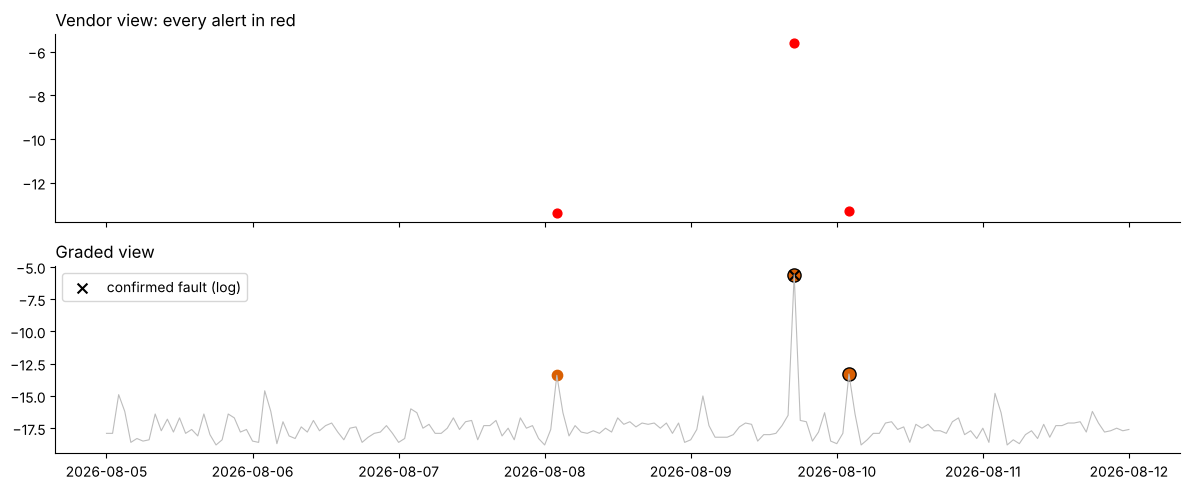

In [13]:
def emphasis(score):
    """Return (colour, marker size, edge colour) for one reading."""
    # TODO: replace the single return below with the four bands
    if score >= 0.90:
        strong = (ACCENT, 90, "k")
        return strong
    elif score >= 0.70:
        moderate = (ACCENT, 55, None)
        return moderate
    elif score >= 0.50:
        subtle = ("none", 55, ACCENT)
        return subtle
    else:
        no_emphasis = (GREY, 0, None)
        return no_emphasis

week = df[(df.freezer_id == "FZ-B2") & (df.timestamp.between("2026-08-05", "2026-08-12"))]
if ready(emphasis(0.95)):
    fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
    a = week[week.ai_flag == 1]; ax[0].scatter(a.timestamp, a.temp_c, color="red", s=40); ax[0].set_title("Vendor view: every alert in red", loc="left")
    ax[1].plot(week.timestamp, week.temp_c, color=GREY, lw=.8)
    for _, r in week[week.ai_score >= 0.5].iterrows():
        col, size, edge = emphasis(r.ai_score)
        ax[1].scatter(r.timestamp, r.temp_c, color=col, s=size, edgecolors=edge)
    f_ = week[week.confirmed_fault == 1]; ax[1].scatter(f_.timestamp, f_.temp_c, marker="x", color="k", s=50, label="confirmed fault (log)")
    ax[1].legend(loc="upper left"); ax[1].set_title("Graded view", loc="left"); plt.tight_layout(); plt.show()

### 7b · "A score of 0.92 means 92%"? Count it.
Wilke: people read probabilities better as **frequencies**. Of all alerts in a score band, how many were real?

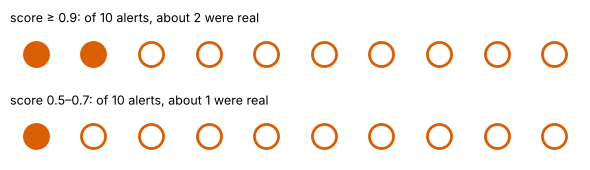

In [14]:
band_hi = df[df.ai_score >= 0.9]
band_lo = df[(df.ai_score >= 0.5) & (df.ai_score < 0.7)]

hi_fault_share = band_hi["confirmed_fault"].mean()
lo_fault_share = band_lo["confirmed_fault"].mean()
real_per_10_hi = round(hi_fault_share * 10)   # TODO: of 10 alerts with score >= 0.9, about how many were real faults? (round to a whole number)
real_per_10_lo = round(lo_fault_share * 10)   # TODO: same for scores 0.5-0.7

if ready(real_per_10_hi, real_per_10_lo):
    fig, ax = plt.subplots(2, 1, figsize=(6, 1.8))
    for a_, k, lab in zip(ax, [real_per_10_hi, real_per_10_lo], ["score ≥ 0.9", "score 0.5–0.7"]):
        for i in range(10): a_.scatter(i, 0, s=300, color=ACCENT if i < k else "white", edgecolors=ACCENT, linewidths=2)
        a_.axis("off"); a_.set_title(f"{lab}: of 10 alerts, about {k} were real", loc="left", fontsize=9)
    plt.tight_layout(); plt.show()

**✏️ Your answer (Part 7):** (a) Why does a red dot at every alert make Ravi's team **more** likely to miss the frozen H2 sensor? Use the words *salience* and *inattentional blindness*. (b) Rewrite vendor statement 6 using frequency framing.

*Your answer:*
(a) Marking every alert in the same bright red gives each one identical *salience*, no matter how confident the underlying score actually is, which conditions the viewer's eye to jump straight to whatever is loudest and reddest on screen. Because the frozen FZ-H2 sensor never actually triggers an alert (it sits at a flat, seemingly ordinary temperature with a score near zero), there's no red dot competing for attention there at all — this is a case of *inattentional blindness*: someone trained to scan for red dots will look right past a perfectly flat, unflagged line and never register that "unchanging for too long" is itself the problem.
(b) **Rewritten statement 6 (frequency framing):** "Out of every 10 alerts scored 0.9 or above, about 2 turn out to be genuine faults. Out of every 10 alerts scored between 0.5 and 0.7, only about 1 is genuine. A higher score does make a fault more likely than a lower-scoring alert, but even the most confident alerts are wrong more often than not, so every alert still needs a human check before a technician is sent out."


---
## Part 8 · Standard deviation vs standard error (vendor statement 8)

The vendor judged a new FZ-B1 reading of **−15.9 °C at 14:00** against the 14:00 baseline.

In [15]:
base = df[(df.freezer_id == "FZ-B1") & (df.hour == 14) & (df.confirmed_fault == 0)]["temp_c"]
mu, sd, n = base.mean(), base.std(), len(base)
new_reading = -15.9

se = sd / np.sqrt(n)        # TODO: standard error of the baseline mean
z_sd = (new_reading - mu) / sd      # TODO: (new_reading - mu) / sd
z_se = (new_reading - mu) / se      # TODO: (new_reading - mu) / se

if ready(se, z_sd, z_se):
    print(f"baseline: mean {mu:.2f} °C, SD {sd:.2f}, n = {n}, SE = {se:.3f}")
    print(f"z using SD = {z_sd:.1f} | z using SE = {z_se:.1f}")

correct_z = "SD"   # TODO: 'SD' or 'SE' - which one should be used to judge a single new reading?

baseline: mean -17.31 °C, SD 0.61, n = 42, SE = 0.094
z using SD = 2.3 | z using SE = 15.0


**✏️ Your answer (Part 8):** In one sentence each, say what the SD and the SE describe, and rewrite vendor statement 8.

*Your answer:*
The standard deviation (SD) captures how much individual readings typically vary around the mean, which makes it the right yardstick for judging whether one *new* reading is unusual. The standard error (SE) captures how precisely we know the *mean itself* — it keeps shrinking as the sample size n grows — so it answers "how confident are we in our estimate of the average," not "how surprising is this particular new data point."
**Rewritten statement 8:** "The new FZ-B1 reading of −15.9 °C at 14:00 sits about 2.3 standard deviations above that freezer's normal 2pm baseline — noticeably warm and worth a look, but far from the extreme 'definite fault' implied by the vendor's '15 standard errors' framing; that inflated figure comes from comparing the reading to the *standard error of the mean* (which shrinks as sample size grows) instead of to the natural spread of individual readings, and it overstates how unusual a single new reading really is."


---
## Part 9 · Triage the vendor report

For each statement decide: **Accept** (correct as stated), **Correct** (useful, but the wording or number must change) or **Reject** (not supported). Then measure the report.

In [16]:
decisions = {
    1: "Reject",   # 97.9% accurate, so trustworthy
    2: "Reject",   # most faults happen around 2 am
    3: "Accept",   # all 10 compressor trips caught
    4: "Reject",   # FZ-H2 had no fault
    5: "Reject",   # -14 °C is abnormal at any time
    6: "Reject",   # score 0.92 = 92% chance
    7: "Reject",   # threshold 0.5 is best
    8: "Correct",   # 15 standard errors: definite fault
}

if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    accepted = sum(v == "Accept" for v in decisions.values())
    print(f"Statements accepted as written: {accepted}/{len(decisions)} ({accepted / len(decisions):.0%})")
    print(pd.Series(decisions).value_counts().to_string())
else:
    print("⚠ Fill in all eight decisions with 'Accept', 'Correct' or 'Reject'.")

Statements accepted as written: 1/8 (12%)
Reject     6
Accept     1
Correct    1


**✏️ Your answer (Part 9):** Sketch (in words or a quick drawing) the **anomaly review view** you would give Ravi's team instead of the vendor's red-dot dashboard. Name at least four parts: main view, context, queue, verification tools, evaluation.

*Your answer:*
**Main view:** a per-freezer time-series line for temperature (with door-opens and compressor kW shown as smaller supporting traces), where alerts use graded emphasis — size/opacity/edge scaled to `ai_score` rather than a single uniform red — so confidence is visible at a glance, and the nightly defrost window is shaded as expected/normal instead of being flagged.
**Context:** each freezer's own hour-of-day baseline (median ± MAD) plotted next to the live reading, so a technician can tell at once whether a value is unusual *for that freezer at that time of day* — directly tackling the contextual-anomaly issue raised by vendor statement 5.
**Queue:** a prioritised worklist of open alerts ranked by score and by the estimated cost of ignoring them (a high-score compressor trip ranked well above a borderline 0.55-score alert at 2 am), with the defrost-window false alarms suppressed or pushed down by default.
**Verification tools:** a one-click path from any alert to the surrounding time window (like the 10-reading window examined in Part 3) and to the freezer's flat-run detector output, letting a technician quickly check whether it's masking, a collective anomaly (flat run), or just the defrost cycle before heading out.
**Evaluation:** a live precision/recall/cost dashboard (built the way Parts 4–5 did) visible to Ravi, refreshed as the maintenance log grows, so the team can track whether the detector — and whatever threshold is in use — is genuinely improving over time, and can justify adjusting the threshold if the cost trade-off shifts.


---
## Reflection

Answer in 2–4 sentences each. There are no right-or-wrong answers here; we are looking for honest thinking about *your own* process.

**1. Automation bias.** Before you checked anything, which vendor statement did you find most convincing? Was it the number, the confident tone, or the red dots? Would you have caught the problem without the maintenance log?

*Your reflection:*
Vendor statement 1 ("97.9% accurate, so its alerts can be trusted") was the most persuasive at first glance, purely on the strength of the number — 97.9% sounds authoritative, and the sentence treats accuracy as if it were self-evidently the right yardstick for trustworthiness. Without the maintenance log, and without realising just how rare real faults are (meaning a detector that never alerts would actually score even higher), I likely would have taken that 97.9% at face value instead of asking for precision and recall.

**2. Who sets the threshold?** The threshold decides how many night call-outs happen and how many freezers spoil. Who at FreshKart should own that choice, and what information should the dashboard show them?

*Your reflection:*
Setting the threshold is really a business trade-off between technician cost and spoilage risk, so it should sit with someone like Ravi (cold-chain lead), working together with operations and finance, rather than being left at whatever default the vendor shipped (0.5). The dashboard should present the full precision/recall/cost sweep across threshold values (as in Part 5), with the relative costs of a missed fault versus a false call-out made explicit and adjustable, turning the choice into a visible, deliberate decision rather than a hidden default.

**3. Missing ground truth.** You had a maintenance log. In real life, faults nobody inspected never get a label. How would that change your precision and recall numbers, and how could the review workflow reduce the problem?

*Your reflection:*
Without a maintenance log, any fault that technicians never physically inspected — because it was never flagged, or was flagged and dismissed — would have no ground-truth label, which would make the computed recall look artificially better than it really is (since unlabelled misses simply can't be counted as false negatives), while precision would remain roughly accurate for the alerts that were actually investigated. A review workflow requiring every alert — and occasionally a random sample of unflagged readings too — to be checked and logged would reduce this bias by generating ground truth for cases the detector currently overlooks, instead of only validating the cases it chose to surface.

**4. Designing against over-trust.** Name one design change (encoding, interaction, wording) that would make technicians *check* an alert rather than simply obey or ignore it.

*Your reflection:*
Swapping the single uniform-red "alert" marker for emphasis graded by the actual score (as built in Part 7a), together with a short frequency-framed note on each alert card (e.g. "about 1 in 10 alerts like this one turn out to be real"), would nudge technicians toward treating every alert as a probability worth verifying, rather than either blindly obeying it or eventually tuning it out after being burned by too many false alarms.
